# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MEDOXIII/FlyRank-Internship-ML/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

# W07 — Content action playbook

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

**Inputs.** The W06 pipeline is re-run here (26-feature allowlist, five client-grouped folds, raw missing values, fold-local median imputation with missingness indicators) and **asserted against the W06 results**, so nothing rests on quoted numbers. Each client is scored only by a model that never saw it (out-of-fold). "Decline" below always means the current decline proxy (see Section 2).

**How to read the queue.** There is one queue per client, ordered by the out-of-fold score (ties by `content_id`); `P1_review_first` is what to look at first. Each row says what to check (`suggested_action`), why the page is there (`primary_reason`, `secondary_codes` and a plain-words `why_in_queue`, which also states what this data shows about that kind of page) and what to be careful about (`caution_flags`). The rank comes from the model score and the reason from observable page signals, so a reason code describes the page and does not explain the score. There is **no pooled cross-client ranking**: scores come from different fold models and are uncalibrated.

**Scope.** A page with no impressions in the previous 30 days cannot be "down", so the proxy is undefined for it. The queue covers pages with impressions in the previous 30 days. This is a scope rule, never a model feature. Review slots go to pages whose archetype has a real review prompt; `LOW_VOLUME` pages are listed as `MONITOR_ONLY` without a rank or a score. Tiers (`P1_review_first`, `P2_review_next`, `P3_backlog`) reflect illustrative review capacity, not a tuned cut.

**Archetype → action.** Each in-scope page gets one primary archetype from observable page signals (rules, not model output). The action is a **review prompt**: a hypothesis for a person to check, not a tested fix. The data can show whether an archetype is associated with the decline proxy; it cannot show that the action works.

| Archetype | Rule (constants in the code cell) | Review prompt |
|---|---|---|
| `LOW_CTR_FOR_POSITION` | visible, position known, CTR in the lowest quartile of its position band (bands closed on the right: (0,3], (3,5], (5,10], (10,20], (20,+); thresholds computed from in-scope visible pages) | Check title, meta description and snippet against search intent and nearby ranking pages |
| `STALE_AND_VISIBLE` | age and visibility thresholds of the Week-4 rule, not already low-CTR | Check freshness; decide update, consolidate or leave |
| `VISIBLE_OTHER` | visible, neither rule | Quick look only if capacity remains |
| `LOW_VOLUME` | below the visibility threshold | Monitor only |

**Caution flags** (can combine with any archetype; `AGE_UNDER_180D` means only that the page is under 180 days old, not that it was launched recently): `TOP1PCT_IMPRESSIONS`, `AGE_UNDER_180D`, `POSITION_MISSING`, `ZERO_ENGAGEMENT`. They add a verification step to the prompt; they do not change the ranking.

**Evidence labels** use descriptive rules set before looking at results, with no confidence interval: `HIGHER_THAN_REST` / `LOWER_THAN_REST` need a gap of at least 5 percentage points in the proxy decline rate and the same direction in at least 70% of eligible clients; anything else is `MIXED`, and too few eligible clients is `UNDERPOWERED`.

**Checks.** W06 measured top-K precision on whole folds pooled across clients, but the queue is per client, so the code re-measures it per client (out-of-fold, clients with enough pages of both kinds) against the client's own prevalence and against the Week-4 rule ordered within the same client, with all in-scope pages as a sensitivity run. The verdict rule is set before the results: at least 8 clients, and AUC above 0.5 and P@20 above prevalence in at least 70% of them. The code also prints how often each caution flag appears in P1, among ranked pages and among all in-scope pages: if a flag is common it describes the typical page and cannot work as a per-page warning.

In [1]:
# ===== Q1: ranked actions + reason codes =====
# ---- Inputs, W06 pipeline re-run, out-of-fold (OOF) scores ----
import json
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

repo_root = next(
    (p for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
     if (p / "data" / "processed" / "refresh_feature_vector.csv").exists()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Could not locate the repository processed feature vector")
OUT_DIR, FIG_DIR = repo_root / "work" / "outputs", repo_root / "work" / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(repo_root / "data" / "processed" / "refresh_feature_vector.csv")
assert len(df) == 30_000, f"Unexpected row count: {len(df):,}"
assert {"client_id", "content_id", "trend_direction", "is_declining_label"}.issubset(df.columns)
assert (df["is_declining_label"].astype(int) == df["trend_direction"].eq("down").astype(int)).all()

numeric_features = [
    "search_volume", "competition", "cpc", "word_count", "char_count",
    "log_impressions_90d", "log_clicks_90d", "log_sessions_90d", "log_ai_sessions_90d",
    "days_with_impressions", "days_with_sessions", "content_age_days", "days_since_last_update",
    "ctr", "avg_position", "engagement_rate", "scroll_rate", "ai_traffic_pct",
]
categorical_features = [
    "competition_level", "content_type", "main_intent",
    "age_tier", "freshness_tier", "word_count_tier", "impression_tier", "position_tier",
]
features = numeric_features + categorical_features
assert len(features) == 26

forbidden_features = {
    "content_id", "client_id", "trend_direction", "trend_pct", "is_declining_label", "measurable_opportunity",
    "impressions_last_30d", "clicks_last_30d", "sessions_last_30d",
    "impressions_prev_30d", "clicks_prev_30d", "sessions_prev_30d",
}
assert set(features).isdisjoint(forbidden_features)

# Raw file aligned to the processed row order (same approach as W06)
raw_df = pd.read_csv(repo_root / "data" / "raw" / "content_refresh_anonymized.csv")
assert raw_df["content_id"].is_unique and df["content_id"].is_unique
raw_by_id = raw_df.set_index("content_id")
assert set(raw_by_id.index) == set(df["content_id"])
raw_model_df = raw_by_id.loc[df["content_id"]].reset_index()
assert raw_model_df["trend_direction"].eq(df["trend_direction"]).all()
assert (raw_model_df["content_id"].to_numpy() == df["content_id"].to_numpy()).all()


def clean_raw(frame):
    out = frame.copy()
    for column in numeric_features:
        if column.startswith("log_"):
            source = column.removeprefix("log_")
            out[column] = np.log1p(pd.to_numeric(out[source], errors="coerce").clip(lower=0))
        else:
            out[column] = pd.to_numeric(out[column], errors="coerce")
        out[column] = out[column].replace([np.inf, -np.inf], np.nan)
    out.loc[out["avg_position"].eq(0), "avg_position"] = np.nan  # zero means missing position
    for column in categorical_features:
        out[column] = out[column].fillna("unknown").astype(str).replace({"": "unknown", "nan": "unknown"})
    return out


raw_model_df = clean_raw(raw_model_df)
y_all = raw_model_df["trend_direction"].eq("down").astype(int)
groups = raw_model_df["client_id"].astype(str)
assert (df["client_id"].astype(str).to_numpy() == groups.to_numpy()).all()
splits = list(GroupKFold(n_splits=5).split(raw_model_df, y_all, groups=groups))
for train_idx, test_idx in splits:
    assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[test_idx])), "A client crossed train/test"


def make_logistic_model():
    preprocessor = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scaler", StandardScaler())]), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ])
    return Pipeline([("preprocessor", preprocessor),
                     ("model", LogisticRegression(class_weight="balanced", max_iter=5000, random_state=42))])


def week4_scores(frame):
    imp = pd.to_numeric(frame["impressions_90d"], errors="coerce")
    return imp.where(frame["content_age_days"].ge(180) & imp.ge(500), 0.0).to_numpy()


def build_queue(frame, scores, method):
    q = pd.DataFrame({
        "content_id": frame["content_id"].to_numpy(),
        "client_id": frame["client_id"].astype(str).to_numpy(),
        "y": frame["y"].to_numpy(),
        "score": np.asarray(scores, dtype=float),
        "impressions": pd.to_numeric(frame["impressions_90d"], errors="coerce").to_numpy(),
        "age": frame["content_age_days"].to_numpy(),
    })
    if method == "rule":   # Week-4 order: score, impressions, age (desc), then content_id (asc)
        keys, ascending = ["score", "impressions", "age", "content_id"], [False, False, False, True]
    else:                  # model: score, then content_id
        keys, ascending = ["score", "content_id"], [False, True]
    return q.sort_values(keys, ascending=ascending, kind="mergesort").reset_index(drop=True)


def topk_precision(queue, k):
    return float(queue["y"].head(k).mean())


# ---- OOF scores: each client is scored only by a model that never saw it ----
KS = (20, 50, 100)
X_all = raw_model_df[features]
oof_score = np.full(len(df), np.nan)
oof_fold = np.zeros(len(df), dtype=int)
fold_rows = []
for fold_number, (tr, te) in enumerate(splits, start=1):
    model = make_logistic_model().fit(X_all.iloc[tr], y_all.iloc[tr])
    scores = model.predict_proba(X_all.iloc[te])[:, 1]
    oof_score[te], oof_fold[te] = scores, fold_number
    test = raw_model_df.iloc[te].assign(y=y_all.iloc[te].to_numpy())
    y_test = test["y"].to_numpy()
    queues = {"model": build_queue(test, scores, "model"),
              "rule": build_queue(test, week4_scores(test), "rule")}
    row = {"fold": fold_number, "test_clients": int(groups.iloc[te].nunique()),
           "prevalence": float(y_test.mean()),
           "model_ROC_AUC": float(roc_auc_score(y_test, scores)),
           "model_AP": float(average_precision_score(y_test, scores))}
    for method, queue in queues.items():
        for k in KS:
            row[f"{method}_P@{k}"] = topk_precision(queue, k)
        row[f"{method}_top50_largest_client_share"] = float(
            queue["client_id"].head(50).value_counts(normalize=True).iloc[0])
    valid = pd.to_numeric(test["impressions_prev_30d"], errors="coerce").gt(0).to_numpy()
    sub, sub_y = test.loc[valid], y_test[valid]
    row["valid_prevalence"] = float(sub_y.mean())
    row["valid_model_ROC_AUC"] = float(roc_auc_score(sub_y, scores[valid]))
    row["valid_model_lift@50"] = topk_precision(build_queue(sub, scores[valid], "model"), 50) - row["valid_prevalence"]
    fold_rows.append(row)
fold_metrics = pd.DataFrame(fold_rows)

assert not np.isnan(oof_score).any() and (oof_fold > 0).all()
assert pd.Series(oof_fold).groupby(groups.to_numpy()).nunique().max() == 1  # one fold (one model) per client

# ---- Reproduction check against the W06 results (C: raw missing + indicators) ----
fm = fold_metrics
f25 = fm[fm["fold"] >= 2]
repro = [
    ("mean model P@20/50/100", [round(fm[f"model_P@{k}"].mean(), 3) for k in KS], [0.760, 0.792, 0.774]),
    ("mean rule P@20/50/100", [round(fm[f"rule_P@{k}"].mean(), 3) for k in KS], [0.530, 0.540, 0.542]),
    ("mean fold prevalence", round(fm["prevalence"].mean(), 3), 0.544),
    ("mean model ROC AUC", round(fm["model_ROC_AUC"].mean(), 3), 0.655),
    ("mean model AP", round(fm["model_AP"].mean(), 3), 0.663),
    ("valid-baseline AUC min/max", (round(fm["valid_model_ROC_AUC"].min(), 3), round(fm["valid_model_ROC_AUC"].max(), 3)), (0.501, 0.627)),
    ("valid-baseline P@50 above subset prevalence in every fold", bool((fm["valid_model_lift@50"] > 0).all()), True),
    ("model top-50 largest-client share, folds 2-5 (min/max)", (round(f25["model_top50_largest_client_share"].min(), 2), round(f25["model_top50_largest_client_share"].max(), 2)), (0.52, 0.66)),
    ("rule top-50 largest-client share (min)", round(fm["rule_top50_largest_client_share"].min(), 2), 0.82),
]


def _py(v):   # plain Python numbers so the table and the metrics JSON do not show np.float64(...)
    if isinstance(v, (list, tuple)):
        return type(v)(_py(x) for x in v)
    if isinstance(v, np.bool_):
        return bool(v)
    if isinstance(v, np.floating):
        return float(v)
    return v


repro = [(n, _py(o), e) for n, o, e in repro]
repro_table = pd.DataFrame([(n, str(o), str(e), o == e) for n, o, e in repro],
                           columns=["check", "this notebook", "W06 result", "match"])
print("W06 re-derived inside W07 (five client-grouped folds, raw missing values, fold-local imputation):")
display(repro_table)
assert repro_table["match"].all(), "W06 numbers were not reproduced; do not continue until this is understood"
print(f"{len(features)} features; no client crosses train/test; every client scored by exactly one fold model.")


# ---- Scope, archetypes, reason codes, evidence ----
MIN_IMPRESSIONS, MIN_AGE_DAYS = 500, 180
# Position bands are closed on the right (pd.cut right=True): (0,3], (3,5], (5,10], (10,20], (20,+); zero position was set to missing
POS_BINS, POS_LABELS = [0, 3, 5, 10, 20, np.inf], ["(0,3]", "(3,5]", "(5,10]", "(10,20]", "(20,+)"]
LOW_CTR_QUANTILE = 0.25
MIN_CLIENT_PAGES, MIN_CLIENTS = 30, 5       # evidence rules (descriptive, no confidence interval)

work = raw_model_df.copy()
work["y"] = y_all.to_numpy()
work["score"] = oof_score
work["fold"] = oof_fold
imp = pd.to_numeric(work["impressions_90d"], errors="coerce")
age = pd.to_numeric(work["content_age_days"], errors="coerce")
prev_imp = pd.to_numeric(work["impressions_prev_30d"], errors="coerce")
eng = pd.to_numeric(work["engagement_rate"], errors="coerce")

# Scope rule (not a model feature): a page with no impressions in the previous 30 days cannot be "down"
work["in_scope"] = prev_imp.gt(0)

visible = imp.ge(MIN_IMPRESSIONS)
has_pos = work["avg_position"].notna()
work["pos_band"] = pd.cut(work["avg_position"], POS_BINS, labels=POS_LABELS)
# Thresholds come from in-scope visible pages with a known position: the population the archetype is evaluated on
ctr_cut = work[visible & has_pos & work["in_scope"]].groupby("pos_band", observed=True)["ctr"].quantile(LOW_CTR_QUANTILE)
ctr_thr = work["pos_band"].astype(object).map(ctr_cut.to_dict()).astype(float)
low_ctr = visible & has_pos & work["ctr"].le(ctr_thr)
stale_visible = age.ge(MIN_AGE_DAYS) & visible

work["primary_reason"] = np.select(
    [low_ctr.to_numpy(), stale_visible.to_numpy(), visible.to_numpy()],
    ["LOW_CTR_FOR_POSITION", "STALE_AND_VISIBLE", "VISIBLE_OTHER"], default="LOW_VOLUME")
work["secondary_codes"] = np.where((low_ctr & stale_visible).to_numpy(), "STALE_AND_VISIBLE", "")

assert MIN_AGE_DAYS == 180, "The AGE_UNDER_180D flag name assumes the 180-day threshold"
caution_masks = {
    "TOP1PCT_IMPRESSIONS": imp.ge(imp.quantile(0.99)),
    "AGE_UNDER_180D": age.lt(MIN_AGE_DAYS),
    "POSITION_MISSING": ~has_pos,
    "ZERO_ENGAGEMENT": eng.eq(0),
}
caution_arrays = [m.to_numpy() for m in caution_masks.values()]
work["caution_flags"] = ["|".join(n for n, hit in zip(caution_masks, row) if hit) for row in zip(*caution_arrays)]

ACTION = {   # review prompts: hypotheses for a person to check, not tested fixes
    "LOW_CTR_FOR_POSITION": "Check title, meta description and snippet against search intent and nearby ranking pages.",
    "STALE_AND_VISIBLE": "Check freshness: outdated facts, dates, links and sections; decide update, consolidate or leave.",
    "VISIBLE_OTHER": "Quick look only if review capacity remains; no specific hypothesis.",
    "LOW_VOLUME": "Monitor only; volume is too low for a reliable read.",
}
CAUTION_TEXT = {
    "TOP1PCT_IMPRESSIONS": "Confirm whether this is a brand or hub page; second reviewer.",
    "AGE_UNDER_180D": "Page is under 180 days old; check whether it is still ramping up before reading a decline.",
    "POSITION_MISSING": "Verify tracking first (no position data).",
    "ZERO_ENGAGEMENT": "Engagement is zero (common here); check once per site whether engagement is tracked for this page type.",
}
work["suggested_action"] = [
    (ACTION[p] + " " + " ".join(CAUTION_TEXT[c] for c in flags.split("|") if c)).strip()
    for p, flags in zip(work["primary_reason"], work["caution_flags"])
]

# Archetype and caution rules use allowed signals only; scope uses the baseline as a filter, never as a feature
assert "log_impressions_90d" in features and {"content_age_days", "avg_position", "ctr", "engagement_rate"} <= set(features)
assert set(work["primary_reason"]) <= set(ACTION)


def compare_groups(frame, mask, min_n):
    """Proxy decline rate inside vs outside a group, plus agreement across clients (client_id only groups)."""
    mask = pd.Series(np.asarray(mask, dtype=bool), index=frame.index)
    n_in, n_out = int(mask.sum()), int((~mask).sum())
    rate_in = float(frame.loc[mask, "y"].mean()) if n_in else np.nan
    rate_out = float(frame.loc[~mask, "y"].mean()) if n_out else np.nan
    g = frame.assign(_m=mask).groupby(["client_id", "_m"])["y"].agg(["size", "mean"]).unstack("_m")
    for stat in ("size", "mean"):
        for flag in (True, False):
            if (stat, flag) not in g.columns:
                g[(stat, flag)] = np.nan
    ok = g[(g[("size", True)] >= min_n) & (g[("size", False)] >= min_n)]
    share = float((ok[("mean", True)] > ok[("mean", False)]).mean()) if len(ok) else np.nan
    return {"n_in": n_in, "n_out": n_out, "rate_in": rate_in, "rate_out": rate_out,
            "diff_pp": (rate_in - rate_out) * 100, "clients": int(len(ok)), "share_higher": share}


def evidence_label(res, pos="HIGHER_THAN_REST", neg="LOWER_THAN_REST"):
    if res["clients"] < MIN_CLIENTS or not np.isfinite(res["share_higher"]):
        return "UNDERPOWERED"
    if res["diff_pp"] >= 5 and res["share_higher"] >= 0.70:
        return pos
    if res["diff_pp"] <= -5 and res["share_higher"] <= 0.30:
        return neg
    return "MIXED"


scope = work[work["in_scope"]].copy()
rows = []
for name in ACTION:
    res = compare_groups(scope, scope["primary_reason"].eq(name), MIN_CLIENT_PAGES)
    rows.append({"archetype": name, "pages_in_scope": res["n_in"], "share_of_scope": res["n_in"] / len(scope),
                 "proxy_decline_rate": res["rate_in"], "rest_rate": res["rate_out"], "diff_pp": res["diff_pp"],
                 "clients_eligible": res["clients"], "share_clients_higher": res["share_higher"],
                 "evidence": evidence_label(res), "review_prompt": ACTION[name]})
archetype_table = pd.DataFrame(rows)

assert LOW_CTR_QUANTILE == 0.25      # the plain-words text below says "lowest quarter"
WHY = {
    "LOW_CTR_FOR_POSITION": "Click-through rate is in the lowest quarter for pages at a similar search position.",
    "STALE_AND_VISIBLE": f"Page is at least {MIN_AGE_DAYS} days old with at least {MIN_IMPRESSIONS} impressions in 90 days.",
    "VISIBLE_OTHER": f"At least {MIN_IMPRESSIONS} impressions in 90 days but no specific pattern.",
    "LOW_VOLUME": f"Fewer than {MIN_IMPRESSIONS} impressions in 90 days: too little for a reliable read.",
}
EVIDENCE_WORDS = {
    "HIGHER_THAN_REST": "pages like this were more often in the decline proxy, in most clients",
    "LOWER_THAN_REST": "pages like this were less often in the decline proxy, in most clients",
    "MIXED": "no consistent link to the decline proxy across clients",
    "UNDERPOWERED": "too few clients to tell",
}
evidence_by_arch = archetype_table.set_index("archetype")["evidence"].to_dict()
scope["why_in_queue"] = [f"{WHY[a]} In this data: {EVIDENCE_WORDS[evidence_by_arch[a]]}." for a in scope["primary_reason"]]

print(f"In scope (impressions in the previous 30 days): {len(scope):,} of {len(work):,} pages "
      f"({len(scope) / len(work):.1%}); proxy decline rate in scope {scope['y'].mean():.3f}, "
      f"overall {work['y'].mean():.3f}.")
print(f"Rules: visible = >= {MIN_IMPRESSIONS} impressions in 90 days; stale = age >= {MIN_AGE_DAYS} days; "
      f"low CTR = lowest {LOW_CTR_QUANTILE:.0%} of CTR within its position band ({', '.join(POS_LABELS)}); "
      f"evidence needs >= {MIN_CLIENTS} clients with >= {MIN_CLIENT_PAGES} pages inside and outside the group.")
display(archetype_table.drop(columns="review_prompt").round(3))


# ---- Ranked queue (within client), tiers, per-client validation ----
REVIEW_SLOTS = 20                       # illustrative review capacity per client per cycle
P1_MAX_RANK, P2_MAX_RANK = REVIEW_SLOTS, 100
MIN_PAGES, MIN_EACH_CLASS = 100, 20     # per-client validation needs enough pages of both kinds
KS_CLIENT = (20, 50)

q_all = scope[["content_id", "client_id", "fold", "score", "y", "primary_reason", "secondary_codes",
               "caution_flags", "suggested_action", "why_in_queue", "impressions_90d", "content_age_days"]].copy()
q_all = q_all.sort_values(["client_id", "score", "content_id"], ascending=[True, False, True], kind="mergesort")

# Review slots go to pages whose archetype has a real review prompt. LOW_VOLUME pages are listed
# as MONITOR_ONLY (no rank): their prompt is "monitor", so they should not consume review slots.
q = q_all[q_all["primary_reason"] != "LOW_VOLUME"].copy()
q["queue_rank"] = q.groupby("client_id").cumcount() + 1            # q_all is already in score order
q["priority_tier"] = np.select([q["queue_rank"] <= P1_MAX_RANK, q["queue_rank"] <= P2_MAX_RANK],
                               ["P1_review_first", "P2_review_next"], default="P3_backlog")
monitor_only = q_all[q_all["primary_reason"] == "LOW_VOLUME"].copy()
monitor_only["queue_rank"] = np.nan
monitor_only["priority_tier"] = "MONITOR_ONLY"
assert q["content_id"].is_unique and monitor_only["content_id"].is_unique
assert len(q) + len(monitor_only) == len(scope)
assert (q.groupby("client_id")["queue_rank"].max() == q.groupby("client_id").size()).all()
p1 = q[q["priority_tier"] == "P1_review_first"]


# ---- Does the within-client ordering help? (OOF scores: each client scored by a model that never saw it) ----
def client_eval_frame(frame, ks=KS_CLIENT):
    rows = []
    for _, g in frame.groupby("client_id"):
        g = g.sort_values(["score", "content_id"], ascending=[False, True], kind="mergesort")
        n, n_pos = len(g), int(g["y"].sum())
        if n < MIN_PAGES or n_pos < MIN_EACH_CLASS or n - n_pos < MIN_EACH_CLASS:
            continue
        rule_q = build_queue(g, week4_scores(g), "rule")
        row = {"pages": n, "prevalence": n_pos / n, "auc": float(roc_auc_score(g["y"], g["score"]))}
        for k in ks:
            row[f"model_P@{k}"] = float(g["y"].head(k).mean())
            row[f"rule_P@{k}"] = topk_precision(rule_q, k)
        rows.append(row)
    return pd.DataFrame(rows)


def summarize_eval(ce):
    n = len(ce)
    if n == 0:
        return {"clients_evaluated": 0, "verdict": "UNDERPOWERED"}
    s = {"clients_evaluated": n, "median_auc": float(ce["auc"].median()),
         "auc_q25": float(ce["auc"].quantile(.25)), "auc_q75": float(ce["auc"].quantile(.75)),
         "share_auc_above_0.5": float((ce["auc"] > 0.5).mean()),
         "median_model_P@20": float(ce["model_P@20"].median()), "median_rule_P@20": float(ce["rule_P@20"].median()),
         "median_prevalence": float(ce["prevalence"].median()),
         "share_P@20_above_prevalence": float((ce["model_P@20"] > ce["prevalence"]).mean()),
         "share_P@20_above_rule": float((ce["model_P@20"] > ce["rule_P@20"]).mean())}
    # Verdict rule set before looking at results: >= 8 clients, AUC > 0.5 and P@20 above prevalence in >= 70% of them
    s["verdict"] = ("UNDERPOWERED" if n < 8 else
                    "SUPPORTED" if (s["share_auc_above_0.5"] >= 0.70 and s["share_P@20_above_prevalence"] >= 0.70
                                    and s["median_auc"] > 0.5) else "MIXED")
    return s


def print_eval(label, s):
    print(f"{label}: {s['clients_evaluated']} clients with >= {MIN_PAGES} pages and >= {MIN_EACH_CLASS} of each class.")
    if s["clients_evaluated"]:
        print(f"  AUC median {s['median_auc']:.3f} (IQR {s['auc_q25']:.3f}-{s['auc_q75']:.3f}); AUC > 0.5 in {s['share_auc_above_0.5']:.0%} of clients.")
        print(f"  P@20 median: model {s['median_model_P@20']:.3f}, rule {s['median_rule_P@20']:.3f}, client prevalence "
              f"{s['median_prevalence']:.3f}; model above prevalence in {s['share_P@20_above_prevalence']:.0%} "
              f"and above the rule in {s['share_P@20_above_rule']:.0%} of clients.")
    print(f"  Verdict: {s['verdict']}")


client_eval, client_eval_all = client_eval_frame(q), client_eval_frame(q_all)
per_client, per_client_all = summarize_eval(client_eval), summarize_eval(client_eval_all)
n_eval, per_client_verdict = per_client["clients_evaluated"], per_client["verdict"]

print(f"Queue: {len(q):,} ranked pages across {q['client_id'].nunique()} clients "
      f"({int((q['priority_tier'] == 'P1_review_first').sum()):,} in P1, {int((q['priority_tier'] == 'P2_review_next').sum()):,} in P2); "
      f"{len(monitor_only):,} LOW_VOLUME pages listed as MONITOR_ONLY.")
print_eval("Per-client validation, RANKED pages (the queue)", per_client)
print_eval("Sensitivity: all in-scope pages including LOW_VOLUME", per_client_all)
display(p1["primary_reason"].value_counts().rename("P1_pages").to_frame().join(
    q["primary_reason"].value_counts().rename("ranked_pages")))


# ---- What the ranked queue is made of ----
in_scope_flags = pd.Series({c: float(scope["caution_flags"].str.contains(c).mean()) for c in caution_masks})
ranked_flags = pd.Series({c: float(q["caution_flags"].str.contains(c).mean()) for c in caution_masks})
p1_flags = pd.Series({c: float(p1["caution_flags"].str.contains(c).mean()) for c in caution_masks})
print("Share of rows carrying each caution: all in-scope pages, ranked pages, P1")
display(pd.DataFrame({"in_scope": in_scope_flags, "ranked": ranked_flags, "P1": p1_flags}).round(3))
print(f"Monitor-only list (LOW_VOLUME): {len(monitor_only):,} pages ({len(monitor_only) / len(scope):.1%} of in scope), listed per client, not ranked.")

for flag in ("ZERO_ENGAGEMENT", "AGE_UNDER_180D"):
    res = compare_groups(scope, caution_masks[flag].loc[scope.index], MIN_CLIENT_PAGES)
    print(f"{flag}: proxy decline rate {res['rate_in']:.3f} with the flag vs {res['rate_out']:.3f} without "
          f"({res['diff_pp']:+.1f} pp); {res['clients']} eligible clients, higher in {res['share_higher']:.0%} "
          f"-> {evidence_label(res, 'HIGHER', 'LOWER')}.")

W06 re-derived inside W07 (five client-grouped folds, raw missing values, fold-local imputation):


,check,this notebook,W06 result,match
0,mean model P@20/50/100,"[0.76, 0.792, 0.774]","[0.76, 0.792, 0.774]",True
1,mean rule P@20/50/100,"[0.53, 0.54, 0.542]","[0.53, 0.54, 0.542]",True
2,mean fold prevalence,0.544,0.544,True
3,mean model ROC AUC,0.655,0.655,True
4,mean model AP,0.663,0.663,True
5,valid-baseline AUC min/max,"(0.501, 0.627)","(0.501, 0.627)",True
6,valid-baseline P@50 above subset prevalence in...,True,True,True
7,"model top-50 largest-client share, folds 2-5 (...","(0.52, 0.66)","(0.52, 0.66)",True
8,rule top-50 largest-client share (min),0.82,0.82,True


26 features; no client crosses train/test; every client scored by exactly one fold model.
In scope (impressions in the previous 30 days): 26,612 of 30,000 pages (88.7%); proxy decline rate in scope 0.611, overall 0.542.
Rules: visible = >= 500 impressions in 90 days; stale = age >= 180 days; low CTR = lowest 25% of CTR within its position band ((0,3], (3,5], (5,10], (10,20], (20,+)); evidence needs >= 5 clients with >= 30 pages inside and outside the group.


,archetype,pages_in_scope,share_of_scope,proxy_decline_rate,rest_rate,diff_pp,clients_eligible,share_clients_higher,evidence
0,LOW_CTR_FOR_POSITION,4470,0.168,0.657,0.602,5.579,16,0.750,HIGHER_THAN_REST
1,STALE_AND_VISIBLE,7095,0.267,0.524,0.643,-11.811,12,0.083,LOWER_THAN_REST
2,VISIBLE_OTHER,5052,0.190,0.653,0.601,5.225,10,0.300,MIXED
3,LOW_VOLUME,9995,0.376,0.630,0.599,3.097,18,0.778,MIXED


Queue: 16,617 ranked pages across 28 clients (478 in P1, 1,402 in P2); 9,995 LOW_VOLUME pages listed as MONITOR_ONLY.
Per-client validation, RANKED pages (the queue): 16 clients with >= 100 pages and >= 20 of each class.
  AUC median 0.624 (IQR 0.604-0.630); AUC > 0.5 in 100% of clients.
  P@20 median: model 0.725, rule 0.475, client prevalence 0.587; model above prevalence in 94% and above the rule in 94% of clients.
  Verdict: SUPPORTED
Sensitivity: all in-scope pages including LOW_VOLUME: 21 clients with >= 100 pages and >= 20 of each class.
  AUC median 0.574 (IQR 0.536-0.627); AUC > 0.5 in 86% of clients.
  P@20 median: model 0.800, rule 0.450, client prevalence 0.644; model above prevalence in 95% and above the rule in 86% of clients.
  Verdict: SUPPORTED


,P1_pages,ranked_pages
primary_reason,,
LOW_CTR_FOR_POSITION,319,4470
STALE_AND_VISIBLE,82,7095
VISIBLE_OTHER,77,5052


Share of rows carrying each caution: all in-scope pages, ranked pages, P1


,in_scope,ranked,P1
TOP1PCT_IMPRESSIONS,0.011,0.018,0.004
AGE_UNDER_180D,0.401,0.403,0.598
POSITION_MISSING,0.000,0.000,0.000
ZERO_ENGAGEMENT,0.693,0.554,0.778


Monitor-only list (LOW_VOLUME): 9,995 pages (37.6% of in scope), listed per client, not ranked.
ZERO_ENGAGEMENT: proxy decline rate 0.638 with the flag vs 0.550 without (+8.8 pp); 18 eligible clients, higher in 78% -> HIGHER.
AGE_UNDER_180D: proxy decline rate 0.705 with the flag vs 0.548 without (+15.6 pp); 10 eligible clients, higher in 80% -> HIGHER.


## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

**Who and for what.** A review aid for a content or SEO team working on **one client site at a time**. The queue suggests which pages to look at first in a review cycle. It supports a human decision about where to look; it does not decide what to change.

**Framing.** The label is `trend_direction == "down"`, a current-window proxy (latest 30 days vs the 30 before), not a future outcome. Features summarize trailing 90-day windows that overlap the label window, so everything is within-window and directional: no causal claims, no future-prediction claims, and scores are ranking scores, not calibrated probabilities. IDs are used only for grouping, joining and tie-breaks.

**Limits** (numbers in the evidence cell below).
- The label is a current-window proxy. The queue does not show which pages will decline, and nothing here estimates the effect of any action.
- The score is a ranking score, not a probability, and is not comparable across clients.
- Features cover trailing 90 days and overlap the label window, and the label itself is a change in impressions that a team can read directly in analytics. Whether the score adds anything beyond reading that trend was not tested.
- Pages with no impressions in the previous 30 days are out of scope.
- Whole-fold figures are higher than figures among in-scope pages. Describe the queue with the in-scope and per-client numbers, not the whole-fold P@50.
- Results depend on which clients are held out; there are 32 pseudonymous clients and no calendar dates.
- `ZERO_ENGAGEMENT` and `AGE_UNDER_180D` are common in this data (Section 1 prints the shares) and the score favours such pages. Whether that reflects launch or ramp patterns, real decline or tracking gaps cannot be separated here.
- Not tested: the provenance of the tier columns, the meaning of `days_since_last_update`, whether missingness indicators partly encode client identity, and the contribution of each feature group.
- Review prompts are standard editorial checks, not tested interventions.

**Decay / refresh insight.** What the data can say: Whether page age or a recent update is associated with the current decline proxy, and whether that holds across clients. Comparisons use in-scope pages and group inside each client (`client_id` is used only for grouping).

What it cannot say: Whether refreshing a page helps. There is no refresh-event column and no before/after measurement, and `days_since_last_update` clusters on a few values, with short values falling inside the label window. The refresh figures reported in the FlyRank summary (supplied as a summary, not verified against the paper) are not reproduced here and are not used as findings.

What a valid refresh test would need: Dated refresh events, a pre-refresh baseline for the same pages, a comparison group of similar unrefreshed pages, and control for seasonality.

Page youth is checked as well, because a decline proxy on a young page can reflect a launch or ramp pattern rather than decay. The printed readings below come from the data. Treat the playbook consequence they print as the insight to carry into the paper.

**Cost / value.** The data has no cost, effort or outcome columns, so this is an **illustrative yield calculation, not an ROI**. Review cost is modeled as minutes per page times review slots on ranked pages. Yield is the share of reviewed pages that are in the current decline proxy, per validated client, for the model queue, the Week-4 rule and random order. Minutes per page and hourly cost are **placeholders** to replace with the team's own. The value of a recovered page and the action success rate are unknown (no before/after data), so break-even is shown as a condition only.

In [2]:
# ===== Q2: intended use and limits =====
# ---- Evidence behind the limits text (every number it relies on) ----
assert raw_model_df["client_id"].nunique() == 32 and len(raw_model_df) == 30_000
fm = fold_metrics
limits_evidence = {
    "pages": len(work), "clients": int(work["client_id"].nunique()),
    "in_scope_share": float(work["in_scope"].mean()),
    "model_P@50_by_fold_min_max": (float(fm["model_P@50"].min()), float(fm["model_P@50"].max())),
    "rule_P@50_by_fold_min_max": (float(fm["rule_P@50"].min()), float(fm["rule_P@50"].max())),
    "prevalence_by_fold_min_max": (float(fm["prevalence"].min()), float(fm["prevalence"].max())),
    "whole_fold_AUC_mean": float(fm["model_ROC_AUC"].mean()),
    "whole_fold_AUC_min_max": (float(fm["model_ROC_AUC"].min()), float(fm["model_ROC_AUC"].max())),
    "valid_baseline_AUC_min_max": (float(fm["valid_model_ROC_AUC"].min()), float(fm["valid_model_ROC_AUC"].max())),
    "valid_baseline_P@50_lift_min_max": (float(fm["valid_model_lift@50"].min()), float(fm["valid_model_lift@50"].max())),
    "per_client_median_AUC": float(client_eval["auc"].median()), "per_client_verdict": per_client_verdict,
    "per_client_all_in_scope_median_AUC": float(client_eval_all["auc"].median()),
}
print(f"Data: {limits_evidence['pages']:,} pages, {limits_evidence['clients']} pseudonymous clients, no calendar dates; "
      f"{limits_evidence['in_scope_share']:.1%} of pages are in scope.")
print("Whole-fold P@50 by fold: model {:.3f}-{:.3f}, rule {:.3f}-{:.3f}, fold prevalence {:.3f}-{:.3f}.".format(
    *limits_evidence["model_P@50_by_fold_min_max"], *limits_evidence["rule_P@50_by_fold_min_max"],
    *limits_evidence["prevalence_by_fold_min_max"]))
print("Whole-fold ROC AUC: mean {:.3f} (range {:.3f}-{:.3f}); among in-scope pages the range is {:.3f}-{:.3f}, "
      "and P@50 lift over in-scope prevalence is {:.3f}-{:.3f}.".format(
          limits_evidence["whole_fold_AUC_mean"], *limits_evidence["whole_fold_AUC_min_max"],
          *limits_evidence["valid_baseline_AUC_min_max"], *limits_evidence["valid_baseline_P@50_lift_min_max"]))
print(f"Within-client on ranked pages (the unit of the queue): median AUC {limits_evidence['per_client_median_AUC']:.3f}; "
      f"verdict {per_client_verdict}; all in-scope pages (sensitivity): median AUC {limits_evidence['per_client_all_in_scope_median_AUC']:.3f}. "
      "Quote these per-client figures, not the whole-fold P@50, when describing the queue.")


# ---- Decay / refresh insight (descriptive) ----
sc = scope.copy()
sc["age_num"] = pd.to_numeric(sc["content_age_days"], errors="coerce")
sc["above_median_age"] = sc["age_num"].gt(sc.groupby("client_id")["age_num"].transform("median"))   # ties at the median fall in the lower group
sc["over_365"] = sc["age_num"].gt(365)
sc["updated_30d"] = pd.to_numeric(sc["days_since_last_update"], errors="coerce").le(30)

decay_specs = [
    ("above vs at/below each client's median age", "pages above their client's median age", sc["above_median_age"], 50),
    ("pages older than 365 days vs the rest", "older than 365 days", sc["over_365"], MIN_CLIENT_PAGES),
    ("updated within 30 days vs not", "recently updated", sc["updated_30d"], MIN_CLIENT_PAGES),
    ("pages younger than 180 days vs the rest", "younger than 180 days", sc["age_num"].lt(MIN_AGE_DAYS), MIN_CLIENT_PAGES),
]
decay_results = {}
for title, label, mask, min_n in decay_specs:
    res = compare_groups(sc, mask, min_n)
    verdict = evidence_label(res, pos="HIGHER", neg="LOWER")
    decay_results[title] = {**res, "verdict": verdict}
    pattern = {"HIGHER": f"{label} declined MORE in most clients", "LOWER": f"{label} declined LESS in most clients",
               "MIXED": "no consistent pattern across clients", "UNDERPOWERED": "too few clients to read a pattern"}[verdict]
    print(f"{title}: {res['n_in']:,} vs {res['n_out']:,} pages; proxy decline rate {res['rate_in']:.3f} vs {res['rate_out']:.3f} "
          f"({res['diff_pp']:+.1f} pp); {res['clients']} eligible clients, higher in {res['share_higher']:.0%} -> {pattern}.")

upd = pd.to_numeric(sc["days_since_last_update"], errors="coerce")
top_days = upd.value_counts(normalize=True).head(3)
print("\nWhy the update column is not a refresh event: the most common days_since_last_update values are "
      + ", ".join(f"{int(v)} ({s:.0%} of in-scope pages)" for v, s in top_days.items())
      + "; values <= 30 fall inside the 30-day label window; there is no pre-update baseline.")
print(f"Age range in scope: {int(sc['age_num'].min())}-{int(sc['age_num'].max())} days; "
      f"{int(sc['over_365'].sum()):,} pages older than 365 days.")

age_verdict = decay_results[decay_specs[0][0]]["verdict"]
young_verdict = decay_results[decay_specs[3][0]]["verdict"]
consequence = [
    "age is associated with MORE decline across clients, so age may support ordering." if age_verdict == "HIGHER"
    else "age alone is not a reliable decline signal here, so STALE_AND_VISIBLE stays a freshness review prompt, "
         "not a prediction that older pages decay."]
if young_verdict == "HIGHER":
    consequence.append("Young pages (under the age threshold) are over-represented in the proxy; a young page's decline may "
                       "reflect a launch or ramp pattern, so AGE_UNDER_180D stays a caution and not a content-decay diagnosis.")
if any(decay_results[s[0]]["clients"] < 10 for s in decay_specs):
    consequence.append("Some comparisons rest on few eligible clients because age is confounded with client; treat them as tentative.")
print("\nPlaybook consequence: " + " ".join(consequence))


# ---- Cost / value (illustrative yield, not ROI) ----
MINUTES_PER_PAGE = 15        # placeholder: replace with the team's own review time
HOURLY_COST = 40             # placeholder, any currency: replace with the team's own rate
ACTION_SUCCESS_RATE = None   # unknown: no before/after outcome data
PAGE_VALUE = None            # unknown: value of one recovered page

cv_rows = []
for k in KS_CLIENT:
    yields = {"model queue": client_eval[f"model_P@{k}"].mean(),
              "Week-4 rule": client_eval[f"rule_P@{k}"].mean(),
              "random order": client_eval["prevalence"].mean()}
    hours = k * MINUTES_PER_PAGE / 60
    for method, y_ in yields.items():
        found = k * y_
        cv_rows.append({"review_slots": k, "method": method, "mean_yield": float(y_),
                        "review_hours": hours, "proxy_declining_pages_found": float(found),
                        "pages_found_per_100_hours": float(found / hours * 100),
                        "cost_per_page_found": float(hours * HOURLY_COST / found) if found > 0 else np.nan})
cost_value = pd.DataFrame(cv_rows)
print(f"Per client per cycle, ranked pages only, {n_eval} validated clients, {MINUTES_PER_PAGE} min/page and {HOURLY_COST}/hour are placeholders. "
      "'Found' means the page is in the current decline proxy, not that a fix will recover it.")
display(cost_value.round(3))
if ACTION_SUCCESS_RATE is None or PAGE_VALUE is None:
    print("Break-even not computed: it needs yield x action success rate x value of a recovered page > cost per reviewed page, "
          "and the last two are unknown here.")
else:
    k0 = KS_CLIENT[0]
    print("Break-even check:", client_eval[f"model_P@{k0}"].mean() * ACTION_SUCCESS_RATE * PAGE_VALUE
          > MINUTES_PER_PAGE / 60 * HOURLY_COST)

Data: 30,000 pages, 32 pseudonymous clients, no calendar dates; 88.7% of pages are in scope.
Whole-fold P@50 by fold: model 0.660-0.900, rule 0.380-0.840, fold prevalence 0.379-0.645.
Whole-fold ROC AUC: mean 0.655 (range 0.612-0.718); among in-scope pages the range is 0.501-0.627, and P@50 lift over in-scope prevalence is 0.137-0.267.
Within-client on ranked pages (the unit of the queue): median AUC 0.624; verdict SUPPORTED; all in-scope pages (sensitivity): median AUC 0.574. Quote these per-client figures, not the whole-fold P@50, when describing the queue.
above vs at/below each client's median age: 11,585 vs 15,027 pages; proxy decline rate 0.595 vs 0.624 (-2.9 pp); 19 eligible clients, higher in 37% -> no consistent pattern across clients.
pages older than 365 days vs the rest: 6,107 vs 20,505 pages; proxy decline rate 0.444 vs 0.661 (-21.7 pp); 7 eligible clients, higher in 29% -> older than 365 days declined LESS in most clients.
updated within 30 days vs not: 17,454 vs 9,158 pa

,review_slots,method,mean_yield,review_hours,proxy_declining_pages_found,pages_found_per_100_hours,cost_per_page_found
0,20,model queue,0.728,5.0,14.562,291.250,13.734
1,20,Week-4 rule,0.475,5.0,9.500,190.000,21.053
2,20,random order,0.583,5.0,11.659,233.182,17.154
3,50,model queue,0.710,12.5,35.500,284.000,14.085
4,50,Week-4 rule,0.498,12.5,24.875,199.000,20.101
5,50,random order,0.583,12.5,29.148,233.182,17.154


Break-even not computed: it needs yield x action success rate x value of a recovered page > cost per reviewed page, and the last two are unknown here.


## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

**Human-review rules.** Before acting on any queue row, a reviewer:
1. Opens the page's analytics and confirms the decline is real (not seasonality, a tracking change or a launch effect).
2. Reads the caution flags. Where `POSITION_MISSING` is set, verifies tracking first. Because `ZERO_ENGAGEMENT` and `AGE_UNDER_180D` are common, checks once per client and page type whether engagement is tracked and whether the page is still in its launch window, instead of per page.
3. Checks the page's business role; brand, hub, legal and pricing pages need an owner's sign-off.
4. Gets a second reviewer for `TOP1PCT_IMPRESSIONS` pages.
5. Records `reviewer_decision` (act, defer or reject) and a note in the queue file; the rejection rate feeds monitoring (Section 4).
6. Works P1 before P2 and does not work the backlog in a cycle where P1 and P2 are unfinished. `MONITOR_ONLY` rows get no review slot; they are rechecked next cycle.

**Do not automate.**
- Publishing, editing, rewriting, redirecting, consolidating, unpublishing or deleting any page from a queue row.
- Acting on the score alone, or treating a tier as a diagnosis.
- Reading the score as a probability or as expected traffic gain.
- Ranking or budgeting across clients from these scores.
- Telling a client or stakeholder that a page "will recover" or that an action "caused" a change.
- Retraining, re-scoring or changing thresholds without a person reviewing the monitoring report.
- Scoring a client or data source that was not part of the validation.

The code below counts how many P1 rows each check touches, so the review workload is visible.

In [3]:
# ===== Q3: human-review load on the ranked queue =====
flag_rows = lambda pattern: int(p1["caution_flags"].str.contains(pattern).sum())
review_checks = pd.DataFrame([
    ("1. Confirm the decline in the page's analytics", "every P1 row", len(p1)),
    ("2. Once per client and page type: is engagement tracked, is the page still ramping up", "P1 rows flagged ZERO_ENGAGEMENT or AGE_UNDER_180D", flag_rows("ZERO_ENGAGEMENT|AGE_UNDER_180D")),
    ("2b. Verify tracking first", "P1 rows flagged POSITION_MISSING", flag_rows("POSITION_MISSING")),
    ("3. Business-role check (brand, hub, legal, pricing)", "every P1 row", len(p1)),
    ("4. Second reviewer", "P1 rows flagged TOP1PCT_IMPRESSIONS", flag_rows("TOP1PCT_IMPRESSIONS")),
    ("5. Record decision and note in the queue file", "every P1 row", len(p1)),
], columns=["check", "applies to", "P1_rows"])
review_load = {"p1_rows": len(p1), "clients_with_p1": int(p1["client_id"].nunique()),
               "max_p1_rows_per_client": int(p1.groupby("client_id").size().max()),
               "checks": review_checks.to_dict("records")}
print(f"P1 holds {len(p1):,} rows across {review_load['clients_with_p1']} clients (at most {review_load['max_p1_rows_per_client']} per client). "
      "Workload of each check on P1:")
display(review_checks)
print("The queue file carries blank reviewer_decision and human_review_notes columns for the act / defer / reject record.")

P1 holds 478 rows across 28 clients (at most 20 per client). Workload of each check on P1:


,check,applies to,P1_rows
0,1. Confirm the decline in the page's analytics,every P1 row,478
1,2. Once per client and page type: is engagemen...,P1 rows flagged ZERO_ENGAGEMENT or AGE_UNDER_180D,419
2,2b. Verify tracking first,P1 rows flagged POSITION_MISSING,0
3,"3. Business-role check (brand, hub, legal, pri...",every P1 row,478
4,4. Second reviewer,P1 rows flagged TOP1PCT_IMPRESSIONS,2
5,5. Record decision and note in the queue file,every P1 row,478


The queue file carries blank reviewer_decision and human_review_notes columns for the act / defer / reject record.


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

A person runs these checks each review cycle from a short report. Score drift is checked per client against that client's own reference scores from the same model version, because scores come from different fold models, are uncalibrated and are only compared inside a client. The stored reference holds each client's bin edges and the share of reference scores in each bin, so a new batch can be checked from the file alone. It is built from the out-of-fold scores of the five fold models, not from a saved production model, so a deployed model needs its own reference; clients without enough pages have no reference and are not covered. The per-client reference is written to `work/outputs/` and stays out of git because it carries `client_id`. Reference values come from this run. Thresholds are un-tuned starting points to agree with the team. A fired trigger means pause and look; nothing retrains, re-scores or changes thresholds automatically.

In [4]:
# ===== Q4: monitoring / retrain triggers (light, manual) =====
# Scores come from different fold models, are uncalibrated and are only compared inside a client, so score drift is
# checked per client against that client's own reference scores from the same model version.
MODEL_VERSION = "w07_logreg_5fold_oof_v1"    # a retrained or re-preprocessed model needs new references
MIN_REF_PAGES, N_BINS = 200, 5


def reference_edges(scores, n_bins=N_BINS):
    """Interior quantile edges of one client's reference scores."""
    return np.quantile(scores, np.linspace(0, 1, n_bins + 1)[1:-1])


def bin_shares(edges, scores):
    return np.bincount(np.searchsorted(edges, scores, side="right"), minlength=len(edges) + 1) / len(scores)


def psi_vs_reference(edges, ref_shares, current_scores, eps=1e-6):
    """PSI of a client's new batch over the stored reference: bin edges plus the reference share in each bin."""
    expected = np.clip(np.asarray(ref_shares, dtype=float), eps, None)
    actual = np.clip(bin_shares(edges, current_scores), eps, None)
    expected, actual = expected / expected.sum(), actual / actual.sum()   # clipping an empty bin must not break sum-to-1
    return float(np.sum((actual - expected) * np.log(actual / expected)))


def reference_row(client_id, scores):
    """What is stored per client: bin edges AND the share of reference scores in each bin."""
    edges, shares = reference_edges(scores), bin_shares(reference_edges(scores), scores)
    return {"client_id": client_id, "model_version": MODEL_VERSION, "n_pages": len(scores),
            **{f"edge_{i + 1}": float(e) for i, e in enumerate(edges)},
            **{f"share_{i + 1}": float(s_) for i, s_ in enumerate(shares)}}


def psi_from_row(row, current_scores):
    """PSI computed from a stored reference row only (no access to the raw reference scores)."""
    edges = np.array([row[f"edge_{i + 1}"] for i in range(N_BINS - 1)])
    shares = np.array([row[f"share_{i + 1}"] for i in range(N_BINS)])
    return psi_vs_reference(edges, shares, current_scores)


rng = np.random.default_rng(42)
ref_rows, null_psi, shifted_psi, self_psi = [], [], [], []
for cid, g in q_all.groupby("client_id"):
    s = g["score"].to_numpy()
    if len(s) < MIN_REF_PAGES:
        continue
    row = reference_row(cid, s)
    ref_rows.append(row)
    self_psi.append(psi_from_row(row, s))             # a batch identical to the reference must give PSI of about 0
    if len(s) >= 2 * MIN_REF_PAGES:                   # smoke tests of the stored-reference method
        perm = rng.permutation(len(s))
        half_a, half_b = s[perm[: len(s) // 2]], s[perm[len(s) // 2:]]
        null_psi.append(psi_from_row(reference_row(cid, half_a), half_b))      # random halves look stable
        shifted_psi.append(psi_from_row(row, s[s > np.median(s)]))             # a truncated batch does not
monitor_reference = pd.DataFrame(ref_rows)
assert len(monitor_reference) > 0 and len(null_psi) > 0
assert max(self_psi) < 1e-9 and np.median(null_psi) < 0.1 and min(shifted_psi) > 0.2

score_drift_meta = {
    "method": "per-client PSI of a new batch over the stored quintile edges and shares of that client's reference, same model version",
    "model_version": MODEL_VERSION, "bins": N_BINS, "min_reference_pages": MIN_REF_PAGES,
    "stored_reference": "per client: bin edges and the reference share in each bin",
    "reference_source": "out-of-fold scores of the five fold models; no production model is saved",
    "clients_with_reference": int(len(monitor_reference)),
    "clients_without_reference": int(q_all["client_id"].nunique() - len(monitor_reference)),
    "smoke_test_clients": len(null_psi), "smoke_test_null_psi_median": float(np.median(null_psi)),
    "smoke_test_null_psi_max": float(np.max(null_psi)), "smoke_test_shifted_psi_min": float(np.min(shifted_psi)),
}
print(f"Score-drift reference: {len(monitor_reference)} of {q_all['client_id'].nunique()} clients with in-scope pages have one "
      f"(>= {MIN_REF_PAGES} pages; the others are not covered), built from out-of-fold scores of the five fold models, "
      f"not a saved production model (tag {MODEL_VERSION}). "
      f"Smoke test on {len(null_psi)} clients: random-half PSI median {np.median(null_psi):.3f}, max {np.max(null_psi):.3f}; "
      f"truncated batch PSI min {np.min(shifted_psi):.3f}.")

reference = {
    "in_scope_share": float(work["in_scope"].mean()),
    "in_scope_proxy_prevalence": float(scope["y"].mean()),
    "missing_share": {c: float(raw_model_df[c].isna().mean()) for c in ["avg_position", "search_volume", "word_count", "scroll_rate"]},
    "median_log_impressions_90d": float(raw_model_df["log_impressions_90d"].median()),
    "per_client_median_AUC": float(client_eval["auc"].median()),
    "per_client_median_P@20": float(client_eval["model_P@20"].median()),
    "P1_age_under_180d_share": float(p1_flags["AGE_UNDER_180D"]), "P1_zero_engagement_share": float(p1_flags["ZERO_ENGAGEMENT"]),
}
triggers = pd.DataFrame([
    ("Input drift", "Missing share of avg_position, search_volume, word_count, scroll_rate vs reference",
     "Any rises by more than 5 percentage points", "Pause scoring; check the data feed and re-run the leakage audit"),
    ("Score drift", "Per client: PSI of the new batch over the stored quintile edges and shares of that client's reference (same model version)",
     f"PSI above 0.2 for a client that has a reference row and at least {MIN_REF_PAGES} pages in the batch", "Check what changed in that client's inputs before trusting its ranking"),
    ("Scope drift", "Share of pages with impressions in the previous 30 days vs reference",
     "Moves by more than 10 percentage points", "Check analytics tracking and the date windows"),
    ("Reviewer rejection", "Share of P1 rows reviewers mark reject",
     "Above 50% for two consecutive cycles", "Review archetype rules and prompts with the reviewers"),
    ("Lost lift", "Within-client P@20 vs that client's in-scope prevalence on the new window",
     "No lift for two consecutive cycles", "Stop using the queue for that client; investigate"),
    ("Queue composition", "Share of P1 rows flagged AGE_UNDER_180D or ZERO_ENGAGEMENT vs reference",
     "Moves by more than 10 percentage points", "Check whether the score is chasing a data artifact; review with the team"),
    ("New client, schema change or retrained model", "A client not seen in validation, a changed column or label definition, or a new model version",
     "Any occurrence", "Re-run the leakage audit and grouped validation, and rebuild the per-client score references"),
    ("Scheduled review", "Time since the last full validation", "Every quarter, as a starting value",
     "Re-run this notebook end to end and compare with the stored metrics JSON"),
], columns=["trigger", "signal", "starting_threshold", "action_if_fired"])
print("Reference values come from this run; thresholds are un-tuned starting points to agree with the team. "
      "A fired trigger means a person pauses and looks; nothing retrains or re-scores automatically.")
display(triggers)
print("Reference:", json.dumps({k: (round(v, 3) if isinstance(v, float) else v) for k, v in reference.items()}))

Score-drift reference: 19 of 31 clients with in-scope pages have one (>= 200 pages; the others are not covered), built from out-of-fold scores of the five fold models, not a saved production model (tag w07_logreg_5fold_oof_v1). Smoke test on 17 clients: random-half PSI median 0.010, max 0.074; truncated batch PSI min 5.153.
Reference values come from this run; thresholds are un-tuned starting points to agree with the team. A fired trigger means a person pauses and looks; nothing retrains or re-scores automatically.


,trigger,signal,starting_threshold,action_if_fired
0,Input drift,"Missing share of avg_position, search_volume, ...",Any rises by more than 5 percentage points,Pause scoring; check the data feed and re-run ...
1,Score drift,Per client: PSI of the new batch over the stor...,PSI above 0.2 for a client that has a referenc...,Check what changed in that client's inputs bef...
2,Scope drift,Share of pages with impressions in the previou...,Moves by more than 10 percentage points,Check analytics tracking and the date windows
3,Reviewer rejection,Share of P1 rows reviewers mark reject,Above 50% for two consecutive cycles,Review archetype rules and prompts with the re...
4,Lost lift,Within-client P@20 vs that client's in-scope p...,No lift for two consecutive cycles,Stop using the queue for that client; investigate
5,Queue composition,Share of P1 rows flagged AGE_UNDER_180D or ZER...,Moves by more than 10 percentage points,Check whether the score is chasing a data arti...
6,"New client, schema change or retrained model","A client not seen in validation, a changed col...",Any occurrence,Re-run the leakage audit and grouped validatio...
7,Scheduled review,Time since the last full validation,"Every quarter, as a starting value",Re-run this notebook end to end and compare wi...


Reference: {"in_scope_share": 0.887, "in_scope_proxy_prevalence": 0.611, "missing_share": {"avg_position": 0.04016666666666667, "search_volume": 0.08226666666666667, "word_count": 0.2566333333333333, "scroll_rate": 0.004166666666666667}, "median_log_impressions_90d": 6.596, "per_client_median_AUC": 0.624, "per_client_median_P@20": 0.725, "P1_age_under_180d_share": 0.598, "P1_zero_engagement_share": 0.778}


## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

`work/outputs/w07_review_queue.csv` (row-level) and `w07_monitoring_reference_by_client.csv` (carries `client_id`) stay out of git. `w07_playbook_metrics.json` (aggregates only, committed) and three figures in `work/figures/` (committed) are the receipts the paper's numbers trace back to. When citing queue performance in the paper, use the per-client figures and keep the label wording ("current decline proxy", "within-window", "decision support").

Queue CSV: 26,612 rows (16,617 ranked, 9,995 monitor-only) -> work\outputs\w07_review_queue.csv; ignored by git (good).


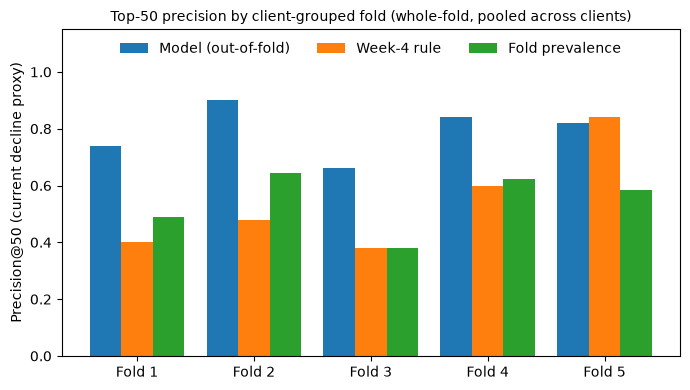

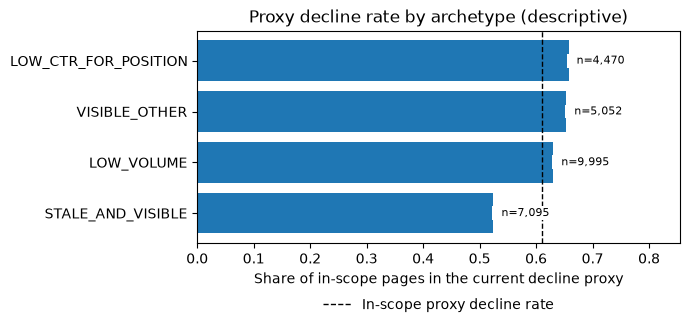

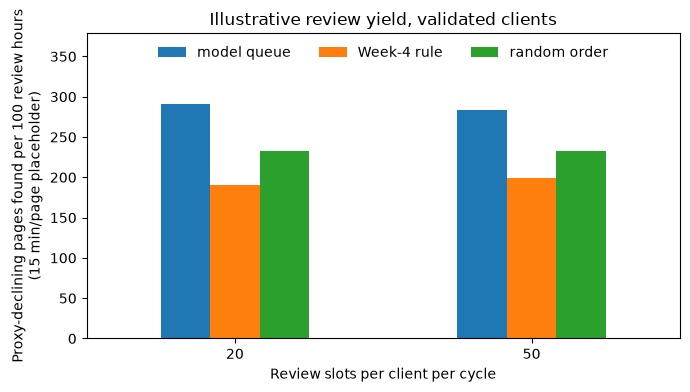

Metrics JSON -> work\outputs\w07_playbook_metrics.json; figures -> w07_fig_p50_by_fold.png, w07_fig_archetype_decline_rate.png, w07_fig_review_yield.png
Score-drift reference by client -> work\outputs\w07_monitoring_reference_by_client.csv; ignored by git (good).
Before committing: run git status; only the notebook, figures and metrics JSON should be staged, not the queue CSV.


In [5]:
# ===== Q5: exports (queue CSV, figures, metrics JSON) =====
QUEUE_PATH = OUT_DIR / "w07_review_queue.csv"
METRICS_PATH = OUT_DIR / "w07_playbook_metrics.json"
REF_PATH = OUT_DIR / "w07_monitoring_reference_by_client.csv"
FIG_PATHS = {"p50": FIG_DIR / "w07_fig_p50_by_fold.png",
             "archetypes": FIG_DIR / "w07_fig_archetype_decline_rate.png",
             "yield": FIG_DIR / "w07_fig_review_yield.png"}

# ---- Queue CSV (row-level, stays out of git; no label, no trend columns) ----
export_cols = ["client_id", "queue_rank", "priority_tier", "content_id", "score_uncalibrated", "primary_reason",
               "secondary_codes", "why_in_queue", "caution_flags", "suggested_action", "reviewer_decision", "human_review_notes"]
queue_final = pd.concat([q, monitor_only]).sort_values(["client_id", "queue_rank", "content_id"], na_position="last", kind="mergesort")
queue_final["queue_rank"] = queue_final["queue_rank"].astype("Int64")
# MONITOR_ONLY rows are not ranked, so they carry no score either (an OOF score exists but is not used for them)
queue_final["score_uncalibrated"] = queue_final["score"].round(4).where(queue_final["priority_tier"] != "MONITOR_ONLY")
queue_export = queue_final.assign(reviewer_decision="", human_review_notes="")[export_cols]
assert set(queue_export.columns).isdisjoint(forbidden_features - {"content_id", "client_id"} | {"y", "fold"})
queue_export.to_csv(QUEUE_PATH, index=False)
monitor_reference.to_csv(REF_PATH, index=False)    # per-client reference carries client_id, so it stays out of git too
ref_check = pd.read_csv(REF_PATH)                  # round trip: the stored file alone must reproduce PSI of about 0
for (_, mem), (_, disk) in zip(monitor_reference.iterrows(), ref_check.iterrows()):
    assert abs(psi_from_row(disk, q_all.loc[q_all["client_id"] == mem["client_id"], "score"].to_numpy())) < 1e-6


def git_ignored(path):
    try:
        code = subprocess.run(["git", "-C", str(repo_root), "check-ignore", "-q", str(path)],
                              capture_output=True).returncode
    except Exception:
        return None
    return {0: True, 1: False}.get(code)   # any other code (e.g. not a git repo) -> unknown


state = git_ignored(QUEUE_PATH)
ref_state = git_ignored(REF_PATH)
print(f"Queue CSV: {len(queue_export):,} rows ({len(q):,} ranked, {len(monitor_only):,} monitor-only) -> {QUEUE_PATH.relative_to(repo_root)}; "
      + {True: "ignored by git (good).", False: "NOT ignored by git: do not commit it.", None: "git not available to check; verify with git status."}[state])

# ---- Figures (aggregates only; no IDs) ----
fig, ax = plt.subplots(figsize=(7, 4))
x, w = np.arange(len(fold_metrics)), 0.27
ax.bar(x - w, fold_metrics["model_P@50"], w, label="Model (out-of-fold)")
ax.bar(x, fold_metrics["rule_P@50"], w, label="Week-4 rule")
ax.bar(x + w, fold_metrics["prevalence"], w, label="Fold prevalence")
ax.set_xticks(x)
ax.set_xticklabels([f"Fold {f}" for f in fold_metrics["fold"]])
ax.set_ylabel("Precision@50 (current decline proxy)")
ax.set_title("Top-50 precision by client-grouped fold (whole-fold, pooled across clients)", fontsize=10)
ax.set_ylim(0, 1.15)
ax.legend(frameon=False, ncol=3, loc="upper center")
fig.tight_layout()
fig.savefig(FIG_PATHS["p50"], dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.5))
order = archetype_table.sort_values("proxy_decline_rate")
ax.barh(order["archetype"], order["proxy_decline_rate"])
ax.axvline(scope["y"].mean(), color="black", linestyle="--", linewidth=1, label="In-scope proxy decline rate")
for i, (rate, n) in enumerate(zip(order["proxy_decline_rate"], order["pages_in_scope"])):
    ax.text(rate, i, f"  n={n:,}", va="center", fontsize=8, zorder=5, bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.set_xlabel("Share of in-scope pages in the current decline proxy")
ax.set_title("Proxy decline rate by archetype (descriptive)")
ax.set_xlim(0, order["proxy_decline_rate"].max() * 1.3)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2))
fig.tight_layout()
fig.savefig(FIG_PATHS["archetypes"], dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
pivot = cost_value.pivot(index="review_slots", columns="method", values="pages_found_per_100_hours")
pivot[["model queue", "Week-4 rule", "random order"]].plot.bar(ax=ax, rot=0)
ax.set_xlabel("Review slots per client per cycle")
ax.set_ylabel(f"Proxy-declining pages found per 100 review hours\n({MINUTES_PER_PAGE} min/page placeholder)")
ax.set_title("Illustrative review yield, validated clients")
ax.set_ylim(0, pivot.to_numpy().max() * 1.3)
ax.legend(frameon=False, ncol=3, loc="upper center")
fig.tight_layout()
fig.savefig(FIG_PATHS["yield"], dpi=150, bbox_inches="tight")
plt.show()


# ---- Metrics JSON (aggregates only; committed) ----
def clean(o):
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (bool, np.bool_)):
        return bool(o)
    if isinstance(o, (int, np.integer)):
        return int(o)
    if isinstance(o, (float, np.floating)):
        return float(o) if np.isfinite(o) else None
    return o


metrics = {
    "framing": "Within-window ranking of a current decline proxy (latest 30 days vs the 30 before); decision support for human review; not a forecast, not causal, scores not calibrated.",
    "w06_reproduction": {n: {"this_notebook": str(o), "w06": str(e)} for n, o, e in repro},
    "fold_metrics": fold_metrics.round(4).to_dict("records"),
    "limits_evidence": limits_evidence,
    "scope": {"rule": "impressions_prev_30d > 0 (scope filter only, never a feature)",
              "in_scope_pages": len(scope), "in_scope_share": float(work["in_scope"].mean()),
              "in_scope_proxy_prevalence": float(scope["y"].mean())},
    "archetypes": archetype_table.round(4).to_dict("records"),
    "queue": {"ranked_rows": len(q), "monitor_only_rows": len(monitor_only), "clients": int(q_all["client_id"].nunique()),
              "tier_counts": queue_final["priority_tier"].value_counts().to_dict(), "review_slots_per_client": REVIEW_SLOTS,
              "ranking_unit": "within client, ranked pages only (LOW_VOLUME listed as MONITOR_ONLY); no pooled cross-client ranking"},
    "per_client_validation": per_client,
    "per_client_validation_all_in_scope_sensitivity": per_client_all,
    "queue_composition": {"P1_caution_shares": p1_flags.to_dict(), "ranked_caution_shares": ranked_flags.to_dict(),
                          "in_scope_caution_shares": in_scope_flags.to_dict(),
                          "P1_archetype_counts": p1["primary_reason"].value_counts().to_dict()},
    "human_review": review_load,
    "decay_refresh": decay_results,
    "cost_value": {"placeholders": {"minutes_per_page": MINUTES_PER_PAGE, "hourly_cost": HOURLY_COST},
                   "rows": cost_value.round(4).to_dict("records")},
    "monitoring_reference": {**reference, "score_drift": score_drift_meta},
    "exports": {"queue_csv": QUEUE_PATH.relative_to(repo_root).as_posix(), "monitoring_reference_csv": REF_PATH.relative_to(repo_root).as_posix(), "metrics_json": METRICS_PATH.relative_to(repo_root).as_posix(),
                "figures": [p.relative_to(repo_root).as_posix() for p in FIG_PATHS.values()]},
}
with open(METRICS_PATH, "w") as f:
    json.dump(clean(metrics), f, indent=2)

print(f"Metrics JSON -> {METRICS_PATH.relative_to(repo_root)}; figures -> "
      + ", ".join(p.name for p in FIG_PATHS.values()))
print(f"Score-drift reference by client -> {REF_PATH.relative_to(repo_root)}; "
      + {True: "ignored by git (good).", False: "NOT ignored by git: do not commit it.", None: "git not available to check; verify with git status."}[ref_state])
print("Before committing: run git status; only the notebook, figures and metrics JSON should be staged, not the queue CSV.")

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.